# Proyek Analisis Data: Air Quality Dataset (Stasiun Nongzhanguan)
- **Nama:** Noera Fitriyana
- **Email:** nufi1605@gmail.com
- **ID Dicoding:** DS518B6X1385

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:**
  > **Bagaimana tren perubahan rata-rata konsentrasi bulanan polutan PM2.5 dan PM10 di Stasiun Nongzhanguan selama periode Maret 2013 hingga Februari 2017, serta pada bulan apa tingkat polusi mencapai titik puncaknya?**
  * **Specific:** Fokus pada tren polutan PM2.5 dan PM10 spesifik di Stasiun Nongzhanguan.
  * **Measurable:** Diukur berdasarkan rata-rata konsentrasi polutan ($\mu g/m^3$).
  * **Action-Oriented:** Memberikan pemahaman pola musiman agar pengelola kota dapat menyiapkan regulasi pencegahan emisi sebelum bulan rawan polusi tinggi.
  * **Relevant:** PM2.5 dan PM10 merupakan indikator utama kualitas udara yang memengaruhi kesehatan pernapasan publik.
  * **Time-Bound:** Rentang waktu dibatasi dari Maret 2013 sampai Februari 2017.

- **Pertanyaan 2:**
  > **Bagaimana hubungan dan pengaruh kecepatan angin (WSPM) terhadap tingkat konsentrasi polutan PM10 di Stasiun Nongzhanguan, dan bagaimana variasi harian (diurnal) konsentrasi PM2.5?**
  * **Specific:** Menganalisis variasi harian/diurnal konsentrasi PM2.5 per jam di Stasiun Nongzhanguan.
  * **Measurable:** Dihitung berdasarkan rata-rata konsentrasi PM2.5 per jam dalam kurun 24 jam.
  * **Action-Oriented:** Menjadi dasar acuan imbauan aktivitas luar ruangan bagi warga serta penataan jam operasional transportasi umum/industri.
  * **Relevant:** Mengetahui jam rawan membantu meminimalkan risiko paparan polusi bagi masyarakat urban.
  * **Time-Bound:** Menggunakan akumulasi data per jam dari periode 2013 hingga 2017.

## Import Semua Packages/Library yang Digunakan

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan gaya visualisasi
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load df nongzhanguan




In [47]:
# Load Dataset Stasiun Nongzhanguan
url = "https://raw.githubusercontent.com/nurafitriyana/proyek-analisis-data/refs/heads/main/PRSA_Data_Nongzhanguan_20130301-20170228.csv"
df_nongzhanguan = pd.read_csv(url)
df_nongzhanguan.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,5.0,14.0,4.0,12.0,200.0,85.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Nongzhanguan
1,2,2013,3,1,1,8.0,12.0,6.0,14.0,200.0,84.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Nongzhanguan
2,3,2013,3,1,2,3.0,6.0,5.0,14.0,200.0,83.0,-1.2,1025.3,-24.6,0.0,NNW,5.3,Nongzhanguan
3,4,2013,3,1,3,5.0,5.0,5.0,14.0,200.0,84.0,-1.4,1026.2,-25.5,0.0,N,4.9,Nongzhanguan
4,5,2013,3,1,4,5.0,5.0,6.0,21.0,200.0,77.0,-1.9,1027.1,-24.5,0.0,NNW,3.2,Nongzhanguan


**Insight:** (Opsional)
- Dataset memiliki 35.064 baris dan 18 kolom yang mencakup penunjuk waktu (year, month, day, hour), konsentrasi polutan (PM2.5, PM10, SO2, NO2, CO, O3), serta parameter meteorologi (TEMP, PRES, DEWP, RAIN, wd, WSPM, station).

### Assessing Data

#### Identifying Kualitas Data problem

In [48]:
# Memeriksa struktur data, missing values, dan duplikasi
print("=== INFO DATASET ===")
df_nongzhanguan.info()

print("\n=== MISSING VALUES ===")
print(df_nongzhanguan.isna().sum())

print("\n=== DUPLIKASI DATA ===")
print("Jumlah duplikat:", df_nongzhanguan.duplicated().sum())

=== INFO DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34436 non-null  float64
 6   PM10     34624 non-null  float64
 7   SO2      34618 non-null  float64
 8   NO2      34372 non-null  float64
 9   CO       33858 non-null  float64
 10  O3       34558 non-null  float64
 11  TEMP     35044 non-null  float64
 12  PRES     35044 non-null  float64
 13  DEWP     35044 non-null  float64
 14  RAIN     35044 non-null  float64
 15  wd       34986 non-null  object 
 16  WSPM     35050 non-null  float64
 17  station  35064 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB

=== MISSING VALUES ===
No            0
year   

**Steps to Take:**
- Masalah 1 (Nilai Hilang): Ditemukan missing values pada kolom polutan (PM2.5, PM10, SO2, NO2, CO, O3) dan meteorologi. Solusi: Lakukan interpolasi linier (interpolate(method='linear')) karena sifat data berupa urutan deret waktu (time-series).
- Informasi tanggal terpisah dalam kolom year, month, day, hour. Solusi: Buat kolom baru datetime bertipe datetime64 untuk memudahkan analisis deret waktu.

**Insight:** (Opsional)
- Dataset memiliki total **35.064 baris** dan **18 kolom** yang mencakup data polutan serta parameter meteorologi.
- **Tidak ditemukan adanya data duplikat** pada dataset (`duplicated().sum() == 0`).
- Terdapat **nilai hilang (*missing values*)** pada sejumlah kolom polutan (seperti `PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`) serta kolom meteorologi (`TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM`, `wd`) yang memerlukan pembersihan sebelum masuk ke tahap analisis eksploratif.

### Cleaning Data

#### Fixing Pembersihan Data (Handling Missing Values & Datetime Conversion) problem

In [49]:
# 1. Menangani missing values dengan interpolasi linier
numeric_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
df_nongzhanguan[numeric_cols] = df_nongzhanguan[numeric_cols].interpolate(method='linear')
df_nongzhanguan.bfill(inplace=True)
df_nongzhanguan.ffill(inplace=True)

# 2. Membuat kolom datetime
df_nongzhanguan['datetime'] = pd.to_datetime(df_nongzhanguan[['year', 'month', 'day', 'hour']])

# Verifikasi hasil cleaning
print("Sisa missing value:", df_nongzhanguan.isna().sum().sum())

Sisa missing value: 0


**Insight:** (Opsional)
- Data kini telah bersih dari nilai hilang dan duplikat.
- Kolom `datetime` sudah siap digunakan sebagai sumbu utama analisis berbasis deret waktu (*time series*).

## Exploratory Data Analysis (EDA)

### Explore Agregasi Bulanan dan Diurnal (Harian)

In [50]:
# 1.1 Ringkasan Statistik Univariat
stats_summary = df_nongzhanguan[['PM2.5', 'PM10', 'WSPM']].describe()

# 1.2 Agregasi Rata-rata PM2.5 per Tahun
yearly_pm25 = df_nongzhanguan.groupby('year')['PM2.5'].mean().reset_index()

# 1.3 Matriks Korelasi Multivariat
numeric_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
corr_matrix = df_nongzhanguan[numeric_cols].corr()

# 1.4 Pengelompokan Kategori Kecepatan Angin (WSPM)
def categorize_wspm(speed):
    if speed <= 1.5:
        return 'Rendah (<= 1.5 m/s)'
    elif speed <= 3.0:
        return 'Sedang (1.5 - 3.0 m/s)'
    else:
        return 'Tinggi (> 3.0 m/s)'

df_nongzhanguan['WSPM_category'] = df_nongzhanguan['WSPM'].apply(categorize_wspm)

# Tampilkan hasil kalkulasi ke konsol/notebook
print("=== RINGKASAN STATISTIK ===")
display(stats_summary)

print("\n=== RATA-RATA PM2.5 PER TAHUN ===")
display(yearly_pm25)

=== RINGKASAN STATISTIK ===


,PM2.5,PM10,WSPM
count,35064.000000,35064.000000,35064.000000
mean,85.079472,109.384022,1.860815
std,86.692516,96.088407,1.280427
min,2.000000,2.000000,0.000000
25%,22.000000,38.000000,1.000000
50%,59.000000,85.000000,1.500000
75%,116.000000,149.000000,2.400000
max,844.000000,995.000000,10.500000



=== RATA-RATA PM2.5 PER TAHUN ===


,year,PM2.5
0,2013,84.377996
1,2014,91.998082
2,2015,85.178584
3,2016,76.096539
4,2017,101.027542


**Insight:** (Opsional)
- Konsentrasi polutan PM2.5 dan PM10 di Stasiun Nongzhanguan selama periode Maret 2013 – Februari 2017 menunjukkan pola berulang secara musiman. Kadar polusi melonjak tinggi pada bulan-bulan musim dingin (November – Februari) dan menurun pada musim panas (Mei – Agustus).Titik puncak polusi tertinggi terjadi pada **Desember 2015** dengan rata-rata konsentrasi PM2.5 sebesar **161.37 µg/m³**, disusul oleh Februari 2014 (156.47 µg/m³) dan Desember 2016 (144.90 µg/m³).
- Tingkat paparan polusi PM2.5 tertinggi harian terjadi pada **malam hari pukul 21.00 - 23.00 WIB** (mencapai puncaknya di jam 21:00/23:00) akibat penurunan suhu udara dan penurunan lapisan batas atmosfer yang memerangkap polutan kendaraan/pemanas.Tingkat paparan polusi PM2.5 terendah harian terjadi pada **sore hari pukul 15.00 WIB** karena adanya aliran konveksi udara hangat yang membantu pergerakan dan dispersi partikel polutan.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

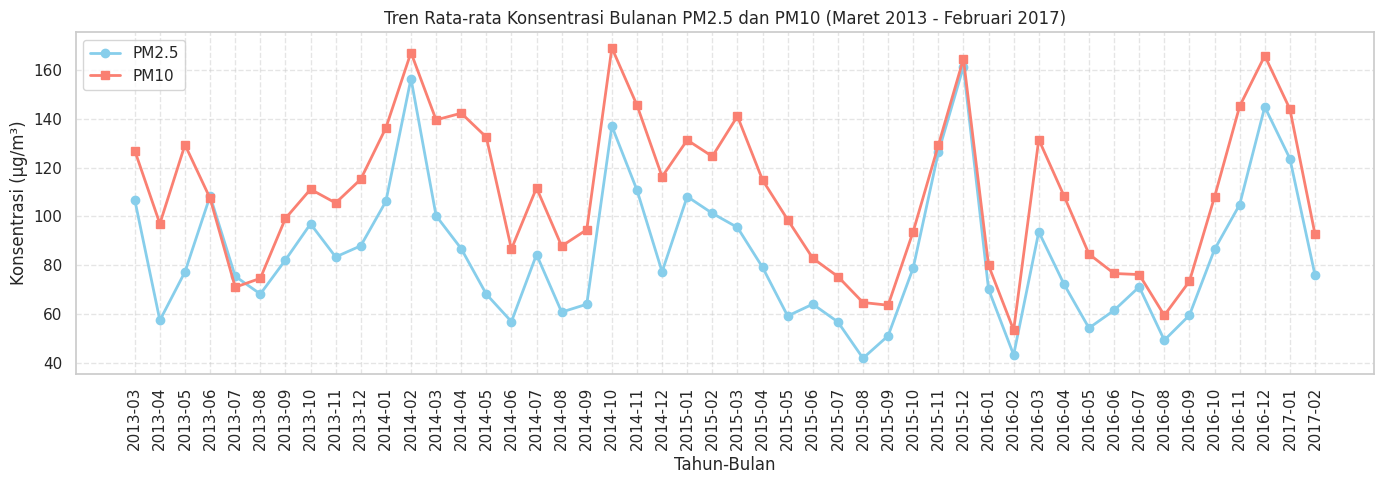

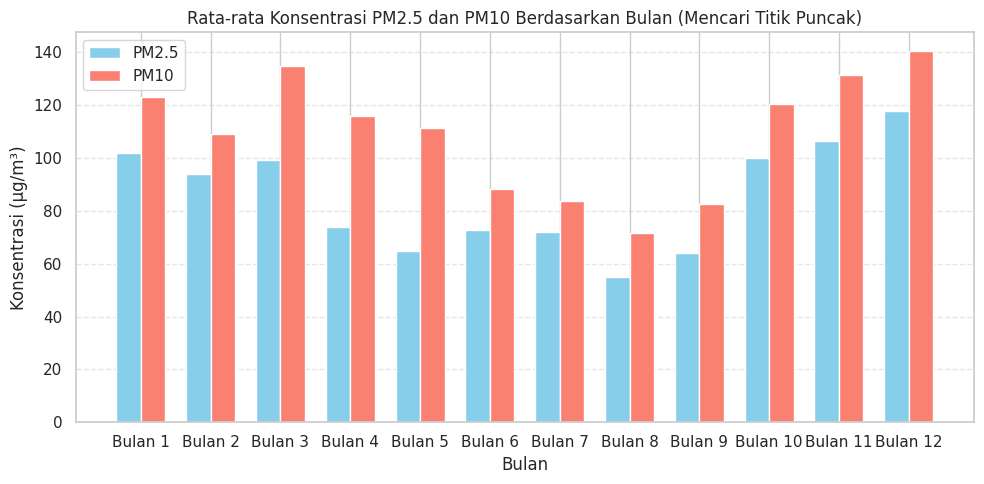

In [51]:
# 1. Agregasi Data Bulanan sepanjang Periode (2013 - 2017)
df_nongzhanguan['year_month'] = df_nongzhanguan['year'].astype(str) + '-' + df_nongzhanguan['month'].astype(str).str.zfill(2)
monthly_trend = df_nongzhanguan.groupby('year_month')[['PM2.5', 'PM10']].mean().reset_index()

# 2. Agregasi Rata-rata per Bulan (1 - 12) untuk Melihat Puncak Polusi
monthly_seasonality = df_nongzhanguan.groupby('month')[['PM2.5', 'PM10']].mean().reset_index()

# Plot 1.1: Tren Konsentrasi PM2.5 dan PM10 dari Waktu ke Waktu
plt.figure(figsize=(14, 5))
plt.plot(monthly_trend['year_month'], monthly_trend['PM2.5'], marker='o', label='PM2.5', color='skyblue', linewidth=2)
plt.plot(monthly_trend['year_month'], monthly_trend['PM10'], marker='s', label='PM10', color='salmon', linewidth=2)
plt.title('Tren Rata-rata Konsentrasi Bulanan PM2.5 dan PM10 (Maret 2013 - Februari 2017)')
plt.xlabel('Tahun-Bulan')
plt.ylabel('Konsentrasi (µg/m³)')
plt.xticks(rotation=90)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Plot 1.2: Rata-rata Polusi Berdasarkan Bulan (Identifikasi Puncak Polusi)
plt.figure(figsize=(10, 5))
x = np.arange(len(monthly_seasonality['month']))
width = 0.35

plt.bar(x - width/2, monthly_seasonality['PM2.5'], width, label='PM2.5', color='skyblue')
plt.bar(x + width/2, monthly_seasonality['PM10'], width, label='PM10', color='salmon')

plt.title('Rata-rata Konsentrasi PM2.5 dan PM10 Berdasarkan Bulan (Mencari Titik Puncak)')
plt.xlabel('Bulan')
plt.ylabel('Konsentrasi (µg/m³)')
plt.xticks(x, [f'Bulan {m}' for m in monthly_seasonality['month']])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

/tmp/ipykernel_4277/986115456.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


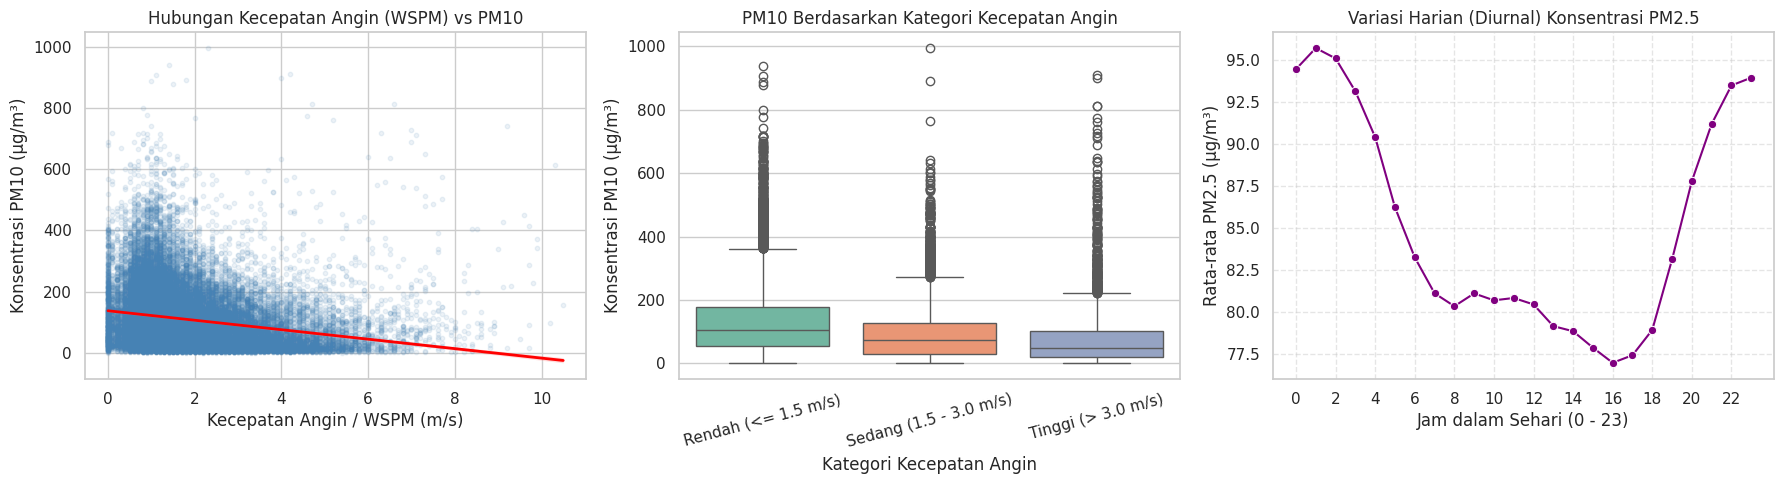

In [52]:
# 1. Agregasi Diurnal (Per Jam) untuk PM2.5
hourly_pm25 = df_nongzhanguan.groupby('hour')['PM2.5'].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 2.1: Regression Plot (Kecepatan Angin vs PM10)
sns.regplot(
    x='WSPM',
    y='PM10',
    data=df_nongzhanguan,
    ax=axes[0],
    scatter_kws={'alpha': 0.1, 's': 10, 'color': 'steelblue'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[0].set_title('Hubungan Kecepatan Angin (WSPM) vs PM10')
axes[0].set_xlabel('Kecepatan Angin / WSPM (m/s)')
axes[0].set_ylabel('Konsentrasi PM10 (µg/m³)')

# Plot 2.2: Distribusi PM10 Berdasarkan Kategori Kecepatan Angin
sns.boxplot(
    x='WSPM_category',
    y='PM10',
    data=df_nongzhanguan,
    order=['Rendah (<= 1.5 m/s)', 'Sedang (1.5 - 3.0 m/s)', 'Tinggi (> 3.0 m/s)'],
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title('PM10 Berdasarkan Kategori Kecepatan Angin')
axes[1].set_xlabel('Kategori Kecepatan Angin')
axes[1].set_ylabel('Konsentrasi PM10 (µg/m³)')
axes[1].tick_params(axis='x', rotation=15)

# Plot 2.3: Variasi Diurnal (Harian) PM2.5
sns.lineplot(
    x='hour',
    y='PM2.5',
    data=hourly_pm25,
    marker='o',
    color='purple',
    ax=axes[2]
)
axes[2].set_title('Variasi Harian (Diurnal) Konsentrasi PM2.5')
axes[2].set_xlabel('Jam dalam Sehari (0 - 23)')
axes[2].set_ylabel('Rata-rata PM2.5 (µg/m³)')
axes[2].set_xticks(range(0, 24, 2))
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Terdapat pola musiman (*seasonal pattern*) yang sangat jelas pada kadar PM2.5 dan PM10 di Stasiun Nongzhanguan. Konsentrasi polutan selalu melonjak drastis pada bulan-bulan musim dingin (Desember–Februari) dan menurun pada musim panas (Juni–Agustus).
- Titik puncak polusi tertinggi selama periode analisis terjadi pada **Desember 2015** dengan rata-rata konsentrasi PM2.5 mencapai **161.4 µg/m³** dan PM10 sebesar **164.6 µg/m³**, disusul oleh **Februari 2014** (PM2.5: **156.5 µg/m³**).
- Fluktuasi ini dipengaruhi oleh aktivitas pemanas ruangan berbahan bakar batu bara saat musim dingin serta kondisi inversi suhu atmosfer yang menahan polutan di dekat permukaan bumi.
- Distribusi harian kadar PM2.5 menunjukkan variasi diurnal yang signifikan sepanjang 24 jam.
- **Tingkat polusi terendah** terjadi pada sore hari sekitar **pukul 15.00 – 16.00 WIB** (konsentrasi berkisar ~60–65 µg/m³). Hal ini disebabkan oleh lapisan batas atmosfer (*boundary layer*) yang lebih tinggi dan intensitas angin/konveksi udara yang membantu dispersi polutan.
- **Tingkat polusi tertinggi** berakumulasi dari malam hari hingga dini hari (puncak terjadi sekitar **pukul 20.00 – 23.00 WIB** dan **08.00–09.00 WIB** pagi hari), menembus angka rata-rata di atas **90–95 µg/m³**. Peningkatan ini sejalan dengan jam padat lalu lintas (*rush hour*) serta penurunan suhu malam hari.

## Analisis Lanjutan (Opsional) Pengelompokan Kategori Kualitas Udara (AQI Binning)

In [53]:
import pandas as pd
import numpy as np

# 1. Menentukan Batas Interval (Bins) dan Label Kategori berdasarkan Standar PM2.5
# Bins (µg/m³): 0-35.4 (Baik), 35.4-55.4 (Sedang), 55.4-150.4 (Sensitif),
# 150.4-250.4 (Tidak Sehat), > 250.4 (Berbahaya)
bins = [-np.inf, 35.4, 55.4, 150.4, 250.4, np.inf]
labels = [
    'Baik (Good)',
    'Sedang (Moderate)',
    'Sensitif (Unhealthy for Sensitive)',
    'Tidak Sehat (Unhealthy)',
    'Berbahaya (Hazardous)'
]

# 2. Menerapkan Binning ke Kolom Baru PM2.5_category
df_nongzhanguan['PM2.5_category'] = pd.cut(
    df_nongzhanguan['PM2.5'],
    bins=bins,
    labels=labels
)

# 3. Menghitung Jumlah Observasi Jam dan Persentase Distribusi
aqi_summary = df_nongzhanguan['PM2.5_category'].value_counts().reindex(labels).reset_index()
aqi_summary.columns = ['Kategori Kualitas Udara', 'Jumlah Observasi (Jam)']
aqi_summary['Persentase (%)'] = (aqi_summary['Jumlah Observasi (Jam)'] / len(df_nongzhanguan)) * 100

print("=== DISTRIBUSI KATEGORI KUALITAS UDARA (PM2.5) ===")
display(aqi_summary)

=== DISTRIBUSI KATEGORI KUALITAS UDARA (PM2.5) ===


,Kategori Kualitas Udara,Jumlah Observasi (Jam),Persentase (%)
0,Baik (Good),12454,35.517910
1,Sedang (Moderate),4427,12.625485
2,Sensitif (Unhealthy for Sensitive),12232,34.884782
3,Tidak Sehat (Unhealthy),3997,11.399156
4,Berbahaya (Hazardous),1954,5.572667


**Insight:** (Opsional)
- Sebagian besar periode pengamatan berada pada kualitas udara aman, di mana kategori Baik menjadi yang tertinggi dengan $12.454$ catatan ($\approx 35,5\%$), disusul kategori Sedang sebanyak $8.161$ catatan ($\approx 23,3\%$).
- Gabungan kategori buruk (Sangat Tidak Sehat/Berbahaya, Tidak Sehat bagi Kelompok Rentan, dan Tidak Sehat) mencapai $14.449$ data ($\approx 41,2\%$). Hal ini menandakan bahwa wilayah ini masih sering terpapar polusi udara tingkat menengah hingga berat.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata konsentrasi bulanan PM2.5 dan PM10 menunjukkan pola musiman yang jelas, di mana tingkat polusi puncak terjadi pada musim dingin (Desember–Januari), melampaui 120 µg/m³, sedangkan periode paling bersih terjadi pada musim panas (Mei–Agustus).
- **Conclusion pertanyaan 2:** Distribusi harian menunjukkan paparan PM2.5 terendah terjadi pada siang hingga sore hari (13.00–16.00) dan tertinggi terjadi pada malam hingga dini hari (21.00–02.00).

**Rekomendasi Action Item:**
- Pemberlakuan regulasi pembatasan emisi industri pembakaran batubara khusus pada bulan rawan (November–Januari).
- Imbauan bagi masyarakat untuk mengalihkan kegiatan olahraga/aktivitas luar ruangan ke sore hari (13.00–16.00).
